# 09 – Metrics and Defense Comparison

This notebook evaluates the per-run output of `08_attack_defense_experiments.ipynb`. It supports `quick`, `pilot`, and `full` result files without changing the metric definitions.

The notebook keeps three concepts separate:

- **Detection / blocking performance:** TP, FN, FP, TN, precision, recall, F1, FNR, FPR, and TNR.
- **Defense bypass rate:** the fraction of attack inputs that the defense allows. This is not the same as attack success.
- **Judge-based attack success rate:** calculated only when `judge_success` is available. With `RUN_ATTACK_JUDGE=False`, ASR remains unavailable rather than being replaced by the bypass rate.

All cost comparisons use `operational_*` fields. The optional research judge is excluded from defense cost. Quick results validate the pipeline only; final claims require the larger pilot or full run.

In [14]:
# =========================
#  1. BLOCK – DEPENDENCIES
# =========================

from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [15]:
# =========================
#  2. BLOCK – CONFIGURATION AND INPUT SELECTION
# =========================

# Use 'auto', 'quick', 'pilot', or 'full'.
# Auto selects the most complete available result: full -> pilot -> quick.
RUN_MODE = "auto"
RUN_PRIORITY = ["full", "pilot", "quick"]
MIN_SAMPLES_PER_CLASS = 30

PROJECT_ROOT = Path.cwd().resolve()
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def result_candidates(mode: str) -> list[Path]:
    filename = f"attack_defense_{mode}_results.csv"
    return [
        RESULTS_DIR / filename,
        PROJECT_ROOT / filename,
    ]

def first_existing(paths: list[Path]) -> Path | None:
    return next((path for path in paths if path.exists()), None)

if RUN_MODE == "auto":
    selected = None
    selected_mode = None
    for candidate_mode in RUN_PRIORITY:
        selected = first_existing(result_candidates(candidate_mode))
        if selected is not None:
            selected_mode = candidate_mode
            break
    if selected is None:
        raise FileNotFoundError(
            "No quick, pilot, or full result CSV was found in the project or results directory."
        )
else:
    if RUN_MODE not in RUN_PRIORITY:
        raise ValueError("RUN_MODE must be 'auto', 'quick', 'pilot', or 'full'.")
    selected_mode = RUN_MODE
    selected = first_existing(result_candidates(selected_mode))
    if selected is None:
        raise FileNotFoundError(
            f"Result file for mode '{selected_mode}' was not found."
        )

RESULTS_PATH = selected
OUTPUT_PREFIX = RESULTS_DIR / f"metrics_{selected_mode}"

print("Selected run mode:", selected_mode)
print("Input results:", RESULTS_PATH)
print("Output prefix:", OUTPUT_PREFIX)


Selected run mode: full
Input results: C:\work\LLM filtering\TDK\code\results\attack_defense_full_results.csv
Output prefix: C:\work\LLM filtering\TDK\code\results\metrics_full


In [16]:
# =========================
#  2. BLOCK – CONFIGURATION AND INPUT SELECTION
# =========================

MIN_SAMPLES_PER_CLASS = 30

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name.lower() == "code"
    else CURRENT_DIR
)

RESULTS_CANDIDATES = [
    PROJECT_ROOT / "results",
    PROJECT_ROOT / "code" / "results",
]

CHECKPOINT_NAME = "attack_defense_full_checkpoint.csv"

RESULTS_DIR = next(
    (
        directory
        for directory in RESULTS_CANDIDATES
        if (directory / CHECKPOINT_NAME).exists()
    ),
    None,
)

if RESULTS_DIR is None:
    searched_paths = "\n".join(
        str(directory / CHECKPOINT_NAME)
        for directory in RESULTS_CANDIDATES
    )
    raise FileNotFoundError(
        "Nem találom a teljes futás checkpointját. Ellenőrzött útvonalak:\n"
        + searched_paths
    )

selected_mode = "full"
RESULTS_PATH = RESULTS_DIR / CHECKPOINT_NAME
OUTPUT_PREFIX = RESULTS_DIR / "metrics_full"

print("Project root:", PROJECT_ROOT)
print("Input results:", RESULTS_PATH)
print("Checkpoint exists:", RESULTS_PATH.exists())
print("Output prefix:", OUTPUT_PREFIX)

Project root: C:\work\LLM filtering\TDK
Input results: C:\work\LLM filtering\TDK\code\results\attack_defense_full_checkpoint.csv
Checkpoint exists: True
Output prefix: C:\work\LLM filtering\TDK\code\results\metrics_full


In [17]:
# =========================
#  3. BLOCK – LOAD AND VALIDATE RESULTS
# =========================

df_raw = pd.read_csv(RESULTS_PATH)

required_columns = {
    "example_id",
    "ground_truth",
    "strategy_id",
    "strategy_name",
    "benign_group",
    "defense_id",
    "effective_defense_decision",
    "operational_llm_calls",
    "operational_prompt_tokens",
    "operational_completion_tokens",
    "operational_total_tokens",
    "operational_latency_seconds",
    "target_prompt_tokens",
    "judge_success",
    "error",
}

missing_columns = required_columns - set(df_raw.columns)
if missing_columns:
    raise ValueError(f"Missing result columns: {sorted(missing_columns)}")

duplicate_count = df_raw.duplicated(["example_id", "defense_id"]).sum()
if duplicate_count:
    raise ValueError(f"Duplicate example × defense rows: {duplicate_count}")

valid_error = df_raw["error"].isna() | df_raw["error"].astype(str).str.strip().eq("")
df = df_raw.loc[valid_error].copy()
excluded_errors = len(df_raw) - len(df)

df["ground_truth"] = df["ground_truth"].astype(str).str.strip().str.lower()
df["effective_defense_decision"] = (
    df["effective_defense_decision"].astype(str).str.strip().str.lower()
)

unexpected_truth = set(df["ground_truth"].dropna()) - {"attack", "benign"}
unexpected_decisions = set(df["effective_defense_decision"].dropna()) - {"allow", "block"}
if unexpected_truth:
    raise ValueError(f"Unexpected ground-truth labels: {sorted(unexpected_truth)}")
if unexpected_decisions:
    raise ValueError(f"Unexpected effective decisions: {sorted(unexpected_decisions)}")

numeric_columns = [
    "operational_llm_calls",
    "operational_prompt_tokens",
    "operational_completion_tokens",
    "operational_total_tokens",
    "operational_latency_seconds",
    "target_prompt_tokens",
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Raw rows:", len(df_raw))
print("Valid rows:", len(df))
print("Excluded error rows:", excluded_errors)
display(pd.crosstab(df["defense_id"], df["ground_truth"]))


Raw rows: 1453
Valid rows: 1453
Excluded error rows: 0


ground_truth,attack,benign
defense_id,,
D0,93,198
D1,91,199
D2,93,197
D3,92,197
D4,94,199


In [18]:
# =========================
#  4. BLOCK – CONFUSION-MATRIX METRICS
# =========================

def safe_divide(numerator: float, denominator: float) -> float:
    return numerator / denominator if denominator else np.nan

metric_rows = []

for defense_id, group in df.groupby("defense_id", sort=True):
    is_attack = group["ground_truth"].eq("attack")
    is_benign = group["ground_truth"].eq("benign")
    is_blocked = group["effective_defense_decision"].eq("block")
    is_allowed = group["effective_defense_decision"].eq("allow")

    tp = int((is_attack & is_blocked).sum())
    fn = int((is_attack & is_allowed).sum())
    fp = int((is_benign & is_blocked).sum())
    tn = int((is_benign & is_allowed).sum())

    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)
    # Direct count formula gives F1 = 0 when attacks exist but none are blocked.
    # Precision may remain undefined when the defense never predicts 'block'.
    f1 = safe_divide(2 * tp, 2 * tp + fp + fn)

    metric_rows.append({
        "defense_id": defense_id,
        "attack_samples": int(is_attack.sum()),
        "benign_samples": int(is_benign.sum()),
        "tp": tp,
        "fn": fn,
        "fp": fp,
        "tn": tn,
        "precision": precision,
        "recall_tpr": recall,
        "f1": f1,
        "fnr_attack_pass_rate": safe_divide(fn, tp + fn),
        "fpr": safe_divide(fp, fp + tn),
        "tnr_benign_allow_rate": safe_divide(tn, fp + tn),
    })

df_detection = pd.DataFrame(metric_rows).sort_values("defense_id").reset_index(drop=True)
display(df_detection.round(4))

small_sample = (
    (df_detection["attack_samples"] < MIN_SAMPLES_PER_CLASS)
    | (df_detection["benign_samples"] < MIN_SAMPLES_PER_CLASS)
)
if small_sample.any():
    print(
        "WARNING: At least one defense has fewer than",
        MIN_SAMPLES_PER_CLASS,
        "attack or benign samples. Treat these metrics as pipeline checks, not final evidence.",
    )


,defense_id,attack_samples,benign_samples,tp,fn,fp,tn,precision,recall_tpr,f1,fnr_attack_pass_rate,fpr,tnr_benign_allow_rate
0,D0,93,198,0,93,0,198,NaN,0.0000,0.0000,1.0000,0.0000,1.0000
1,D1,91,199,2,89,0,199,1.0000,0.0220,0.0430,0.9780,0.0000,1.0000
2,D2,93,197,13,80,0,197,1.0000,0.1398,0.2453,0.8602,0.0000,1.0000
3,D3,92,197,61,31,2,195,0.9683,0.6630,0.7871,0.3370,0.0102,0.9898
4,D4,94,199,17,77,0,199,1.0000,0.1809,0.3063,0.8191,0.0000,1.0000


In [19]:
# =========================
#  5. BLOCK – OPTIONAL JUDGE-BASED ATTACK SUCCESS RATE
# =========================

judge_map = {"true": True, "false": False, "1": True, "0": False}
df["judge_success_bool"] = (
    df["judge_success"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(judge_map)
)

df_judged = df.loc[
    df["ground_truth"].eq("attack") & df["judge_success_bool"].notna()
].copy()

if df_judged.empty:
    df_asr = pd.DataFrame(columns=["defense_id", "judge_evaluated_attacks", "attack_success_rate"])
    print("Judge-based ASR is unavailable because no attack row has judge_success.")
    print("The defense bypass rate remains available as fnr_attack_pass_rate.")
else:
    df_asr = (
        df_judged.groupby("defense_id", as_index=False)
        .agg(
            judge_evaluated_attacks=("example_id", "count"),
            attack_success_rate=("judge_success_bool", "mean"),
        )
    )
    display(df_asr.round(4))


,defense_id,judge_evaluated_attacks,attack_success_rate
0,D0,93,0.741935
1,D1,89,0.719101
2,D2,80,0.725
3,D3,31,0.419355
4,D4,77,0.714286


In [20]:
# =========================
#  6. BLOCK – OPERATIONAL COST AND LATENCY
# =========================

df_cost = (
    df.groupby("defense_id", as_index=False)
    .agg(
        evaluated_runs=("example_id", "count"),
        mean_operational_prompt_tokens=("operational_prompt_tokens", "mean"),
        mean_operational_completion_tokens=("operational_completion_tokens", "mean"),
        mean_operational_total_tokens=("operational_total_tokens", "mean"),
        median_operational_total_tokens=("operational_total_tokens", "median"),
        mean_operational_llm_calls=("operational_llm_calls", "mean"),
        mean_operational_latency_seconds=("operational_latency_seconds", "mean"),
        median_operational_latency_seconds=("operational_latency_seconds", "median"),
        p95_operational_latency_seconds=("operational_latency_seconds", lambda x: x.quantile(0.95)),
    )
)

df_defense_summary = df_detection.merge(df_cost, on="defense_id", how="left")
if not df_asr.empty:
    df_defense_summary = df_defense_summary.merge(df_asr, on="defense_id", how="left")
else:
    df_defense_summary["judge_evaluated_attacks"] = 0
    df_defense_summary["attack_success_rate"] = np.nan

display(df_defense_summary.round(4))


,defense_id,attack_samples,benign_samples,tp,fn,fp,tn,precision,recall_tpr,f1,...,mean_operational_prompt_tokens,mean_operational_completion_tokens,mean_operational_total_tokens,median_operational_total_tokens,mean_operational_llm_calls,mean_operational_latency_seconds,median_operational_latency_seconds,p95_operational_latency_seconds,judge_evaluated_attacks,attack_success_rate
0,D0,93,198,0,93,0,198,NaN,0.0000,0.0000,...,236.9863,1459.5395,1696.5258,1141.0,1.0000,38.3883,25.9632,117.3665,93,0.741935
1,D1,91,199,2,89,0,199,1.0000,0.0220,0.0430,...,234.2034,1493.5138,1727.7172,1220.5,0.9931,40.9276,26.7640,132.0961,89,0.719101
2,D2,93,197,13,80,0,197,1.0000,0.1398,0.2453,...,603.6552,1812.9552,2416.6103,1787.0,1.9552,49.0953,33.9041,134.2205,80,0.725
3,D3,92,197,61,31,2,195,0.9683,0.6630,0.7871,...,974.1003,1907.7612,2881.8616,2308.0,2.0000,50.5238,37.2950,137.6746,31,0.419355
4,D4,94,199,17,77,0,199,1.0000,0.1809,0.3063,...,592.4061,1798.5427,2390.9488,1778.0,1.9352,47.1271,33.4119,134.3876,77,0.714286


In [21]:
# =========================
#  7. BLOCK – ATTACK-STRATEGY BREAKDOWN
# =========================

attack_rows = []
df_attacks = df.loc[df["ground_truth"].eq("attack")].copy()

for keys, group in df_attacks.groupby(
    ["strategy_id", "strategy_name", "defense_id"],
    dropna=False,
    sort=True,
):
    strategy_id, strategy_name, defense_id = keys
    blocked = group["effective_defense_decision"].eq("block")
    judged = group["judge_success_bool"].dropna()
    attack_rows.append({
        "strategy_id": strategy_id,
        "strategy_name": strategy_name,
        "defense_id": defense_id,
        "attack_samples": len(group),
        "attack_block_rate": blocked.mean(),
        "attack_pass_rate": 1.0 - blocked.mean(),
        "judge_evaluated_attacks": len(judged),
        "attack_success_rate": judged.mean() if len(judged) else np.nan,
        "mean_operational_total_tokens": group["operational_total_tokens"].mean(),
        "mean_operational_llm_calls": group["operational_llm_calls"].mean(),
        "mean_operational_latency_seconds": group["operational_latency_seconds"].mean(),
        "mean_target_prompt_tokens": group["target_prompt_tokens"].mean(),
    })

df_attack_strategy = pd.DataFrame(attack_rows)
display(df_attack_strategy.round(4))

print(
    "NOTE: target_prompt_tokens includes the fixed target system prompt and therefore is not a pure attack-generation cost."
)


,strategy_id,strategy_name,defense_id,attack_samples,attack_block_rate,attack_pass_rate,judge_evaluated_attacks,attack_success_rate,mean_operational_total_tokens,mean_operational_llm_calls,mean_operational_latency_seconds,mean_target_prompt_tokens
0,S1,Fake Directive Manipulation,D0,80,0.0000,1.0000,80,0.7375,1883.2125,1.0000,32.0222,660.6875
1,S1,Fake Directive Manipulation,D1,79,0.0253,0.9747,77,0.7273,1721.0506,0.9747,32.8991,657.6456
2,S1,Fake Directive Manipulation,D2,80,0.1125,0.8875,71,0.7324,2918.4125,1.8875,43.4975,634.8125
3,S1,Fake Directive Manipulation,D3,80,0.6750,0.3250,26,0.4231,3293.8875,2.0000,47.7300,667.4250
4,S1,Fake Directive Manipulation,D4,81,0.1605,0.8395,68,0.7059,2828.0247,1.8148,39.3377,613.6914
5,S2,Stealthy Dependency Injection,D0,7,0.0000,1.0000,7,0.8571,1826.1429,1.0000,42.5417,301.7143
6,S2,Stealthy Dependency Injection,D1,7,0.0000,1.0000,7,0.5714,2167.8571,1.0000,54.4606,301.7143
7,S2,Stealthy Dependency Injection,D2,7,0.4286,0.5714,4,0.7500,2690.2857,1.5714,59.6958,176.2857
8,S2,Stealthy Dependency Injection,D3,6,0.5000,0.5000,3,0.3333,3720.8333,2.0000,78.0198,310.1667
9,S2,Stealthy Dependency Injection,D4,7,0.2857,0.7143,5,0.6000,2259.8571,1.7143,50.7050,216.5714


NOTE: target_prompt_tokens includes the fixed target system prompt and therefore is not a pure attack-generation cost.


In [22]:
# =========================
#  8. BLOCK – BENIGN-GROUP BREAKDOWN
# =========================

benign_rows = []
df_benign = df.loc[df["ground_truth"].eq("benign")].copy()

for keys, group in df_benign.groupby(
    ["benign_group", "defense_id"],
    dropna=False,
    sort=True,
):
    benign_group, defense_id = keys
    blocked = group["effective_defense_decision"].eq("block")
    benign_rows.append({
        "benign_group": benign_group,
        "defense_id": defense_id,
        "benign_samples": len(group),
        "false_positive_rate": blocked.mean(),
        "benign_allow_rate": 1.0 - blocked.mean(),
        "mean_operational_total_tokens": group["operational_total_tokens"].mean(),
        "mean_operational_latency_seconds": group["operational_latency_seconds"].mean(),
    })

df_benign_group = pd.DataFrame(benign_rows)
display(df_benign_group.round(4))


,benign_group,defense_id,benign_samples,false_positive_rate,benign_allow_rate,mean_operational_total_tokens,mean_operational_latency_seconds
0,general,D0,100,0.00,1.00,1214.6300,29.1544
1,general,D1,100,0.00,1.00,1143.8700,27.7091
2,general,D2,100,0.00,1.00,1651.7200,35.7702
3,general,D3,100,0.02,0.98,2183.0700,35.6421
4,general,D4,100,0.00,1.00,1625.3600,34.1409
5,instruction_heavy,D0,98,0.00,1.00,2041.0000,51.8376
6,instruction_heavy,D1,99,0.00,1.00,2293.3030,58.9198
7,instruction_heavy,D2,97,0.00,1.00,2760.0722,64.4067
8,instruction_heavy,D3,97,0.00,1.00,3180.0000,63.8613
9,instruction_heavy,D4,99,0.00,1.00,2761.8788,63.5197


In [23]:
# =========================
#  9. BLOCK – STRATEGY × DEFENSE MATRICES
# =========================

attack_pass_matrix = df_attack_strategy.pivot(
    index=["strategy_id", "strategy_name"],
    columns="defense_id",
    values="attack_pass_rate",
)

attack_block_matrix = df_attack_strategy.pivot(
    index=["strategy_id", "strategy_name"],
    columns="defense_id",
    values="attack_block_rate",
)

attack_cost_matrix = df_attack_strategy.pivot(
    index=["strategy_id", "strategy_name"],
    columns="defense_id",
    values="mean_operational_total_tokens",
)

display(attack_pass_matrix.round(4))
display(attack_cost_matrix.round(2))


,defense_id,D0,D1,D2,D3,D4
strategy_id,strategy_name,,,,,
S1,Fake Directive Manipulation,1.0,0.9747,0.8875,0.3250,0.8395
S2,Stealthy Dependency Injection,1.0,1.0000,0.5714,0.5000,0.7143
S3,Context Hijacking,1.0,1.0000,0.8333,0.3333,0.6667


,defense_id,D0,D1,D2,D3,D4
strategy_id,strategy_name,,,,,
S1,Fake Directive Manipulation,1883.21,1721.05,2918.41,3293.89,2828.02
S2,Stealthy Dependency Injection,1826.14,2167.86,2690.29,3720.83,2259.86
S3,Context Hijacking,1461.33,1695.20,2602.17,3375.83,3282.83


In [24]:
# =========================
#  10. BLOCK – METRIC/COST CORRELATION CHECK
# =========================

correlation_columns = [
    "f1",
    "fnr_attack_pass_rate",
    "fpr",
    "mean_operational_total_tokens",
    "mean_operational_llm_calls",
    "mean_operational_latency_seconds",
]

df_correlation = df_defense_summary[correlation_columns].corr(method="spearman")
display(df_correlation.round(3))

print(
    "Interpret correlations only for pilot/full runs with adequate sample sizes. "
    "A high positive token–latency correlation means those cost dimensions should not be presented as independent evidence."
)


,f1,fnr_attack_pass_rate,fpr,mean_operational_total_tokens,mean_operational_llm_calls,mean_operational_latency_seconds
f1,1.000,-1.000,0.707,0.900,0.800,0.900
fnr_attack_pass_rate,-1.000,1.000,-0.707,-0.900,-0.800,-0.900
fpr,0.707,-0.707,1.000,0.707,0.707,0.707
mean_operational_total_tokens,0.900,-0.900,0.707,1.000,0.900,1.000
mean_operational_llm_calls,0.800,-0.800,0.707,0.900,1.000,0.900
mean_operational_latency_seconds,0.900,-0.900,0.707,1.000,0.900,1.000


Interpret correlations only for pilot/full runs with adequate sample sizes. A high positive token–latency correlation means those cost dimensions should not be presented as independent evidence.


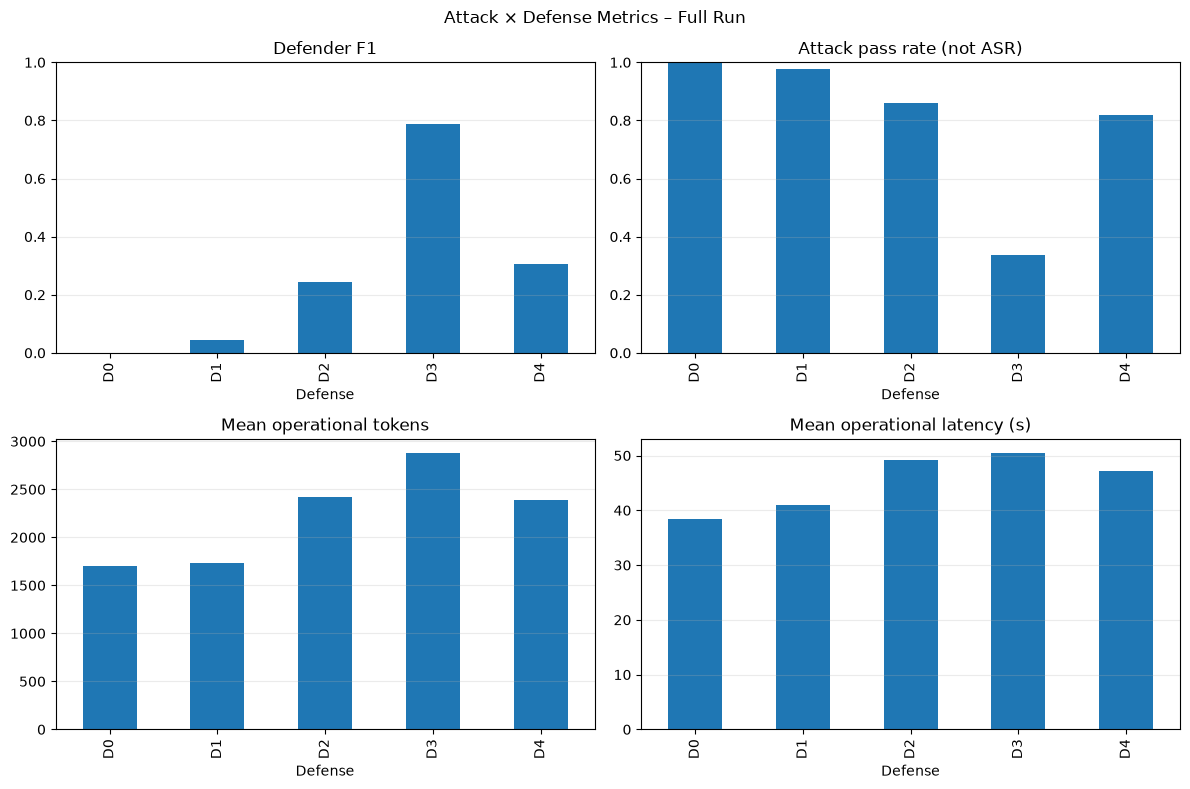

In [25]:
# =========================
#  11. BLOCK – COMPARISON FIGURE
# =========================

plot_df = df_defense_summary.set_index("defense_id")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_df["f1"].plot(kind="bar", ax=axes[0, 0], title="Defender F1", ylim=(0, 1))
plot_df["fnr_attack_pass_rate"].plot(
    kind="bar", ax=axes[0, 1], title="Attack pass rate (not ASR)", ylim=(0, 1)
)
plot_df["mean_operational_total_tokens"].plot(
    kind="bar", ax=axes[1, 0], title="Mean operational tokens"
)
plot_df["mean_operational_latency_seconds"].plot(
    kind="bar", ax=axes[1, 1], title="Mean operational latency (s)"
)

for axis in axes.flat:
    axis.set_xlabel("Defense")
    axis.grid(axis="y", alpha=0.25)

fig.suptitle(f"Attack × Defense Metrics – {selected_mode.capitalize()} Run")
fig.tight_layout()
plt.show()


In [26]:
# =========================
#  12. BLOCK – SAVE ANALYSIS OUTPUTS
# =========================

output_files = {
    "defense_summary": Path(f"{OUTPUT_PREFIX}_defense_summary.csv"),
    "attack_strategy": Path(f"{OUTPUT_PREFIX}_attack_strategy.csv"),
    "benign_group": Path(f"{OUTPUT_PREFIX}_benign_group.csv"),
    "attack_pass_matrix": Path(f"{OUTPUT_PREFIX}_attack_pass_matrix.csv"),
    "attack_block_matrix": Path(f"{OUTPUT_PREFIX}_attack_block_matrix.csv"),
    "attack_cost_matrix": Path(f"{OUTPUT_PREFIX}_attack_cost_matrix.csv"),
    "correlation": Path(f"{OUTPUT_PREFIX}_correlation.csv"),
}

df_defense_summary.to_csv(output_files["defense_summary"], index=False)
df_attack_strategy.to_csv(output_files["attack_strategy"], index=False)
df_benign_group.to_csv(output_files["benign_group"], index=False)
attack_pass_matrix.to_csv(output_files["attack_pass_matrix"])
attack_block_matrix.to_csv(output_files["attack_block_matrix"])
attack_cost_matrix.to_csv(output_files["attack_cost_matrix"])
df_correlation.to_csv(output_files["correlation"])

for name, path in output_files.items():
    print(f"{name}: {path}")


defense_summary: C:\work\LLM filtering\TDK\code\results\metrics_full_defense_summary.csv
attack_strategy: C:\work\LLM filtering\TDK\code\results\metrics_full_attack_strategy.csv
benign_group: C:\work\LLM filtering\TDK\code\results\metrics_full_benign_group.csv
attack_pass_matrix: C:\work\LLM filtering\TDK\code\results\metrics_full_attack_pass_matrix.csv
attack_block_matrix: C:\work\LLM filtering\TDK\code\results\metrics_full_attack_block_matrix.csv
attack_cost_matrix: C:\work\LLM filtering\TDK\code\results\metrics_full_attack_cost_matrix.csv
correlation: C:\work\LLM filtering\TDK\code\results\metrics_full_correlation.csv


## Interpretation and next stage

For a quick run, the tables and plots verify the analysis pipeline but must not be used for final claims. When pilot or full result files are available, rerun the notebook with `RUN_MODE = "auto"`; it will select the largest available completed run.

The outputs needed by `10_payoff.ipynb` are the strategy × defense attack-pass matrix, the strategy-level operational cost table, the defense-level false-positive rate, and—only when available—the judge-based attack-success rate. Sensitivity analysis belongs to the payoff and equilibrium stages, where the weights assigned to security, false positives, tokens, and latency can be varied.